# 第十一轮：有限来源下的信息时效对照

固定完整2,588场2023比赛、0.5阈值，比较同一模型的旧历史与补充近期结果后的输入。
只运行两组成对算法、三次共享逻辑回归拟合；没有重新选参数或混合权重。
2021冻结选择为 **无候选**，2022 gate为 **retain_original_history_recommendation**。
此局部机制选择不能直接替换更强的既有模型。正式历史推荐保留规则及完整选择见
[frozen_selection.json](results/round11/freshness/frozen_selection.json)。70%目标仍未达成，最终年份继续封存。

## 同批比赛比较

| model | information_regime | correct | accuracy | mean_log_loss | additional_correct_for_70 |
| --- | --- | --- | --- | --- | --- |
| overall_elo_stale | 原T−21历史输入 | 1640 | 0.633694 | 0.639146 | 172 |
| overall_elo_fresh | Tier B有限近期结果，含公开时效假设 | 1642 | 0.634467 | 0.638342 | 170 |
| rank_rating_logistic_stale | 原T−21历史输入 | 1678 | 0.648377 | 0.622797 | 134 |
| rank_rating_logistic_fresh | Tier B有限近期结果，含公开时效假设 | 1678 | 0.648377 | 0.622267 | 134 |
| previous_probability_recommendation | 原T−21历史输入 | 1696 | 0.655332 | 0.609407 | 116 |
| previous_round5_exploration | 原T−21历史输入 | 1715 | 0.662674 | 0.609871 | 97 |
| rank_reference | 原历史输入 / 旧基准 | 1640 | 0.633694 | 0.629796 | 172 |
| market_lambda1 | 历史输入；训练期市场监督 | 1712 | 0.661515 | 0.604599 | 100 |
| history_linear_C0.03_alpha1 | 当前开盘价＋T−21历史修正；缺失回退R4 | 1760 | 0.680062 | 0.596723 | 52 |
| raw_market | 当前末盘价优先；缺失用开盘或R4回退 | 1752 | 0.676971 | 0.587691 | 60 |

![第十一轮比较](results/round11/round11_comparison.png)

最高旧市场观察1760/2588=68.01%仍是**未被开发期选择**的一行；与纯历史模型的信息条件不同，
不能称为本轮提升或SOTA。R4/R5上下文行的较早年份曾参与旧选择，不进入本轮机制选择。

## 配对变化与有限覆盖

| algorithm | stale_correct | fresh_correct | accuracy_improvement | log_loss_change | probability_changed_rows | classification_changed_rows | exact_fallback_rows |
| --- | --- | --- | --- | --- | --- | --- | --- |
| overall_elo | 1640 | 1642 | 0.000773 | -0.000804 | 118 | 2 | 2354 |
| rank_rating_logistic | 1678 | 1678 | 0.000000 | -0.000530 | 118 | 0 | 2354 |

| season | total_target_matches | qualified_pairs | qualified_source_editions | qualified_target_editions | target_edition_rows | direct_participant_target_rows |
| --- | --- | --- | --- | --- | --- | --- |
| 2021 | 2388 | 4 | 2 | 4 | 168 | 42 |
| 2022 | 2528 | 5 | 3 | 3 | 183 | 90 |
| 2023 | 2588 | 6 | 4 | 5 | 234 | 118 |

30个按时间固定的来源赛事中，18个有当前官方完赛上界文本（含1个较晚回顾），12个未解决；
其中仅9个独立source edition实际提供增量，组成15对source-target关系。
2023有234行所在赛事获准增加历史，直接涉及118行球员；覆盖数字不是准确率分母。
概率实际变化数及分类翻转数在上表。所有没有增量的行精确沿用各自stale输入与概率。
只有有限早季来源经过核查，不能据此否定全赛季更新历史的价值。

即使把本轮输入发生变化的每一行都假设预测正确，其余固定行保持原预测，乐观上界仍为：

| algorithm | modifiable_rows | optimistic_correct_bound | optimistic_accuracy_bound |
| --- | --- | --- | --- |
| overall_elo | 118 | 1669 | 0.644900 |
| rank_rating_logistic | 118 | 1705 | 0.658810 |

这是使用已查看2023标签计算的事后诊断上界，不是新模型或来源选择规则。
它说明仅在这个固定输入支持范围里调模型的局限，不能替代更广泛的数据证据。

资格使用明确的**Tier B公开结果可用/稳定、赛程一致性假设**：官方已完赛报道日期的全球保守上界
必须早于独立目标开始日下界。当前正文不是历史不可变网页快照，来源完赛报道也不逐条认证完整签表。
拒绝、未核和时间重叠均保留fallback；没有依照2023错例选择赛事或缩小全体比赛。

按赛事日期块配对的accuracy/loss区间及2021/2022完整结果见
[summary.json](results/round11/freshness/summary.json)、[matched_controls.csv](results/round11/freshness/matched_controls.csv)。
这些区间没有校正已进行的广泛搜索；2022 gate及2023均已重复使用，不能当独立最终确认。

## 复跑与审计

在现有依赖和前五轮已复建的环境中，拟合到新的输出目录，避免覆盖冻结运行：

```bash
.venv/bin/python -m scripts.train_freshness_round11 --output /tmp/atp-round11-reproduction --approved-protocol-sha256 690c60196e3b8700157036c5632e5b17190c86c102843530d7f48c972eed1ce7 --approved-manifest-sha256 54281191164bdcfae2cc3cc71cc53db080653d4b6137686f960581517b10dc9d
.venv/bin/python -m scripts.audit_freshness_round11
.venv/bin/python -m scripts.report_round11
```

第一条在独立目录复跑；后两条默认审计/呈现仓库原冻结产物，不自动切换到复跑目录。
无需重新抓取网页。资格ledger与所有引用文件必须匹配冻结哈希；发现证据变化应建新实验，不能重写旧结果。
模型保存在freshness目录的model_2021.joblib、model_2022.joblib和frozen_models.joblib，
权重/训练矩阵为本地可复建文件。完整审计范围及限制见
[artifact_audit.json](results/round11/freshness/artifact_audit.json)，常规测试见[verification.json](results/round11/verification.json)。

独立实现重新计算全部763项来源资格，以及36,421行的两项新旧rating特征，误差均为0。
三套保存模型的7,504行×4列概率、手工线性预测、两列旧参考概率与指标均精确复现；
交换球员/置换批次最大误差2.22e−16且不改分类。六组成对区间独立复算最大差4.34e−19。
没有重跑优化轨迹，没有重新审定原始每场结果，也没有把所有326项旧特征说成独立重建。

常规环境 **343 tests /109 subtests通过，8个可选Torch测试跳过**。独立代码审查发现并列准确率
用浮点相减可能影响tie-break，但协调者启动拟合早于暂停消息到达，修复在本次运行后落盘。
已保留与执行哈希逐字匹配的[原runner](results/round11/freshness/original_train_freshness_round11.py)，
仅把selector改为整数净正确数；本次2021为−3和0，无候选，前后决定一致。
没有重拟合或改写原概率、模型和冻结选择。
[修正与源码差异记录](results/round11/freshness/selection_correction.json)明确区分实际旧代码运行和今后复跑修正版。

[精确协议](docs/research/round11_freshness_protocol.md) ·
[来源资格](results/round11/completion/qualified_pairs.json) ·
[独立证据审查](docs/research/round11_availability_review.md)


In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
root = Path.cwd()
display(pd.read_csv(root/'results/round11/overview_comparison.csv'))

,model,matches,correct,accuracy,mean_log_loss,brier,recommended,plot_label,branch,information_regime,additional_correct_for_70
0,previous_round5_exploration,2588,1715,0.662674,0.609871,0.211658,False,R5 accuracy exploration,freshness,原T−21历史输入,97
1,previous_probability_recommendation,2588,1696,0.655332,0.609407,0.211493,True,R4 historical reference,freshness,原T−21历史输入,116
2,rank_rating_logistic_fresh,2588,1678,0.648377,0.622267,0.216903,False,Rank + ratings / bounded fresher history,freshness,Tier B有限近期结果，含公开时效假设,134
3,rank_rating_logistic_stale,2588,1678,0.648377,0.622797,0.217126,False,Rank + ratings / original history,freshness,原T−21历史输入,134
4,overall_elo_fresh,2588,1642,0.634467,0.638342,0.222986,False,Overall Elo / bounded fresher history,freshness,Tier B有限近期结果，含公开时效假设,170
5,overall_elo_stale,2588,1640,0.633694,0.639146,0.223312,False,Overall Elo / original history,freshness,原T−21历史输入,172
6,rank_reference,2588,1640,0.633694,0.629796,0.220156,NaN,Ranking baseline,prior,原历史输入 / 旧基准,172
7,market_lambda1,2588,1712,0.661515,0.604599,0.209549,NaN,R7 market-supervised student,prior,历史输入；训练期市场监督,100
8,history_linear_C0.03_alpha1,2588,1760,0.680062,0.596723,0.206387,NaN,Opening history (unselected),prior,当前开盘价＋T−21历史修正；缺失回退R4,52
9,raw_market,2588,1752,0.676971,0.587691,0.202766,NaN,Raw latest available price,prior,当前末盘价优先；缺失用开盘或R4回退,60


In [2]:
display(pd.read_csv(root/'results/round11/freshness/matched_controls.csv'))

,season,algorithm,matches,stale_correct,fresh_correct,accuracy_improvement,log_loss_change,edition_covered_rows,direct_player_covered_rows,rating_changed_rows,probability_changed_rows,probability_changed_over_1e12_rows,classification_changed_rows,exact_fallback_rows
0,2021,overall_elo,2388,1498,1495,-0.001256,-0.000101,168,42,42,42,42,3,2220
1,2021,rank_rating_logistic,2388,1519,1519,0.000000,-0.000046,168,42,42,42,42,0,2220
2,2022,overall_elo,2528,1635,1639,0.001582,-0.000408,183,90,90,90,90,4,2345
3,2022,rank_rating_logistic,2528,1657,1658,0.000396,-0.000255,183,90,90,90,90,1,2345
4,2023,overall_elo,2588,1640,1642,0.000773,-0.000804,234,118,118,118,118,2,2354
5,2023,rank_rating_logistic,2588,1678,1678,0.000000,-0.000530,234,118,118,118,118,0,2354


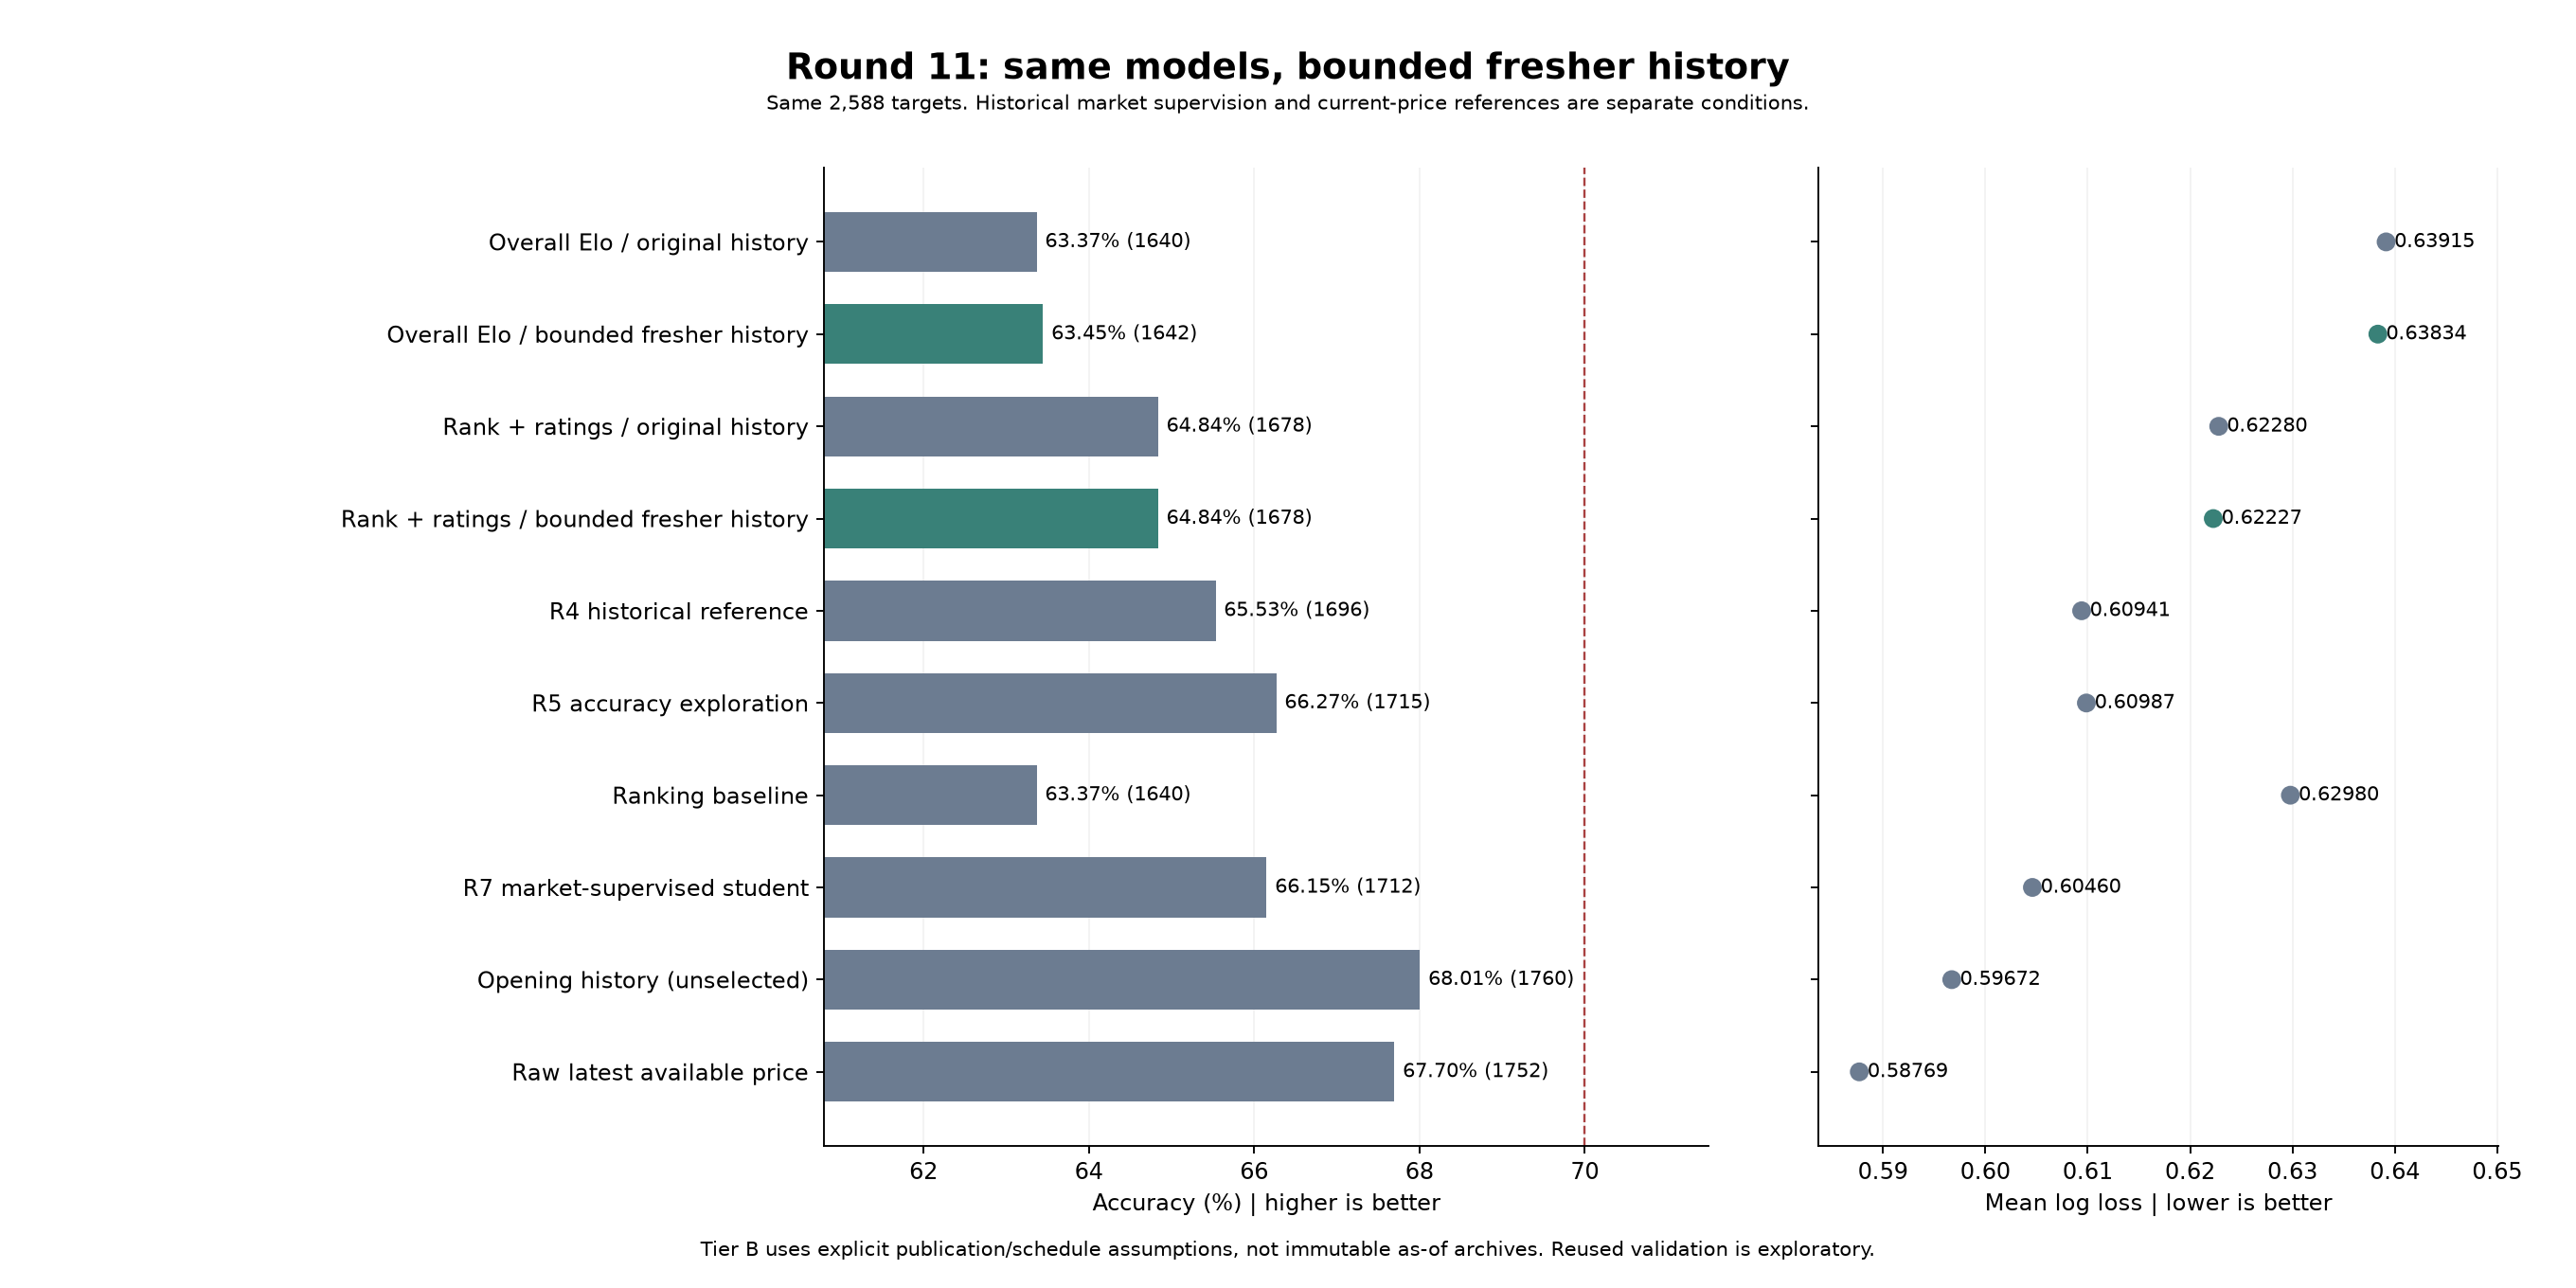

In [3]:
display(Image(filename=str(root/'results/round11/round11_comparison.png')))